# TimeGAN vs GRU
One-second books, midpoint log returns and training-only scaling.
KL uses 32 training-range bins plus tails; SSIM compares 16 generated seconds after identical 48-second histories.
Run all in the project kernel (`uv run --locked jupyter lab`); replay requires the same CPU and locked environment.

In [1]:
from pathlib import Path
import sys, torch
sys.path.insert(0, str(Path.cwd() if Path("dataset.py").exists() else Path.cwd().parent))
from dataset import LOBSTERLevel10Dataset, WindowDataset
from modules import TimeGAN
from train import TrainingConfig, TimeGANTrainer
from evaluation import compare_timegan_gru
torch.set_num_threads(1); torch.manual_seed(0); torch.use_deterministic_algorithms(True)
data = LOBSTERLevel10Dataset(sampling_interval_seconds=1)
config = TrainingConfig(batch_size=32, autoencoder_steps=200, transition_steps=200, joint_steps=500,
    discriminator_learning_rate=1e-4, context_loss_weight=0.01, price_moment_weight=100,
    conditional_drift_weight=100, gradient_diagnostic_interval=0)
model = TimeGAN(latent_dims=32, noise_dims=32)
trainer = TimeGANTrainer(model, config, return_mean=float(data.feature_mean[0]), return_std=float(data.feature_std[0]))
losses = trainer.fit(torch.utils.data.DataLoader(WindowDataset(data.features, 64), batch_size=32, shuffle=True))

TimeGAN    0.1800
GRU        0.2641
Name: Training continuation SSIM, dtype: float64

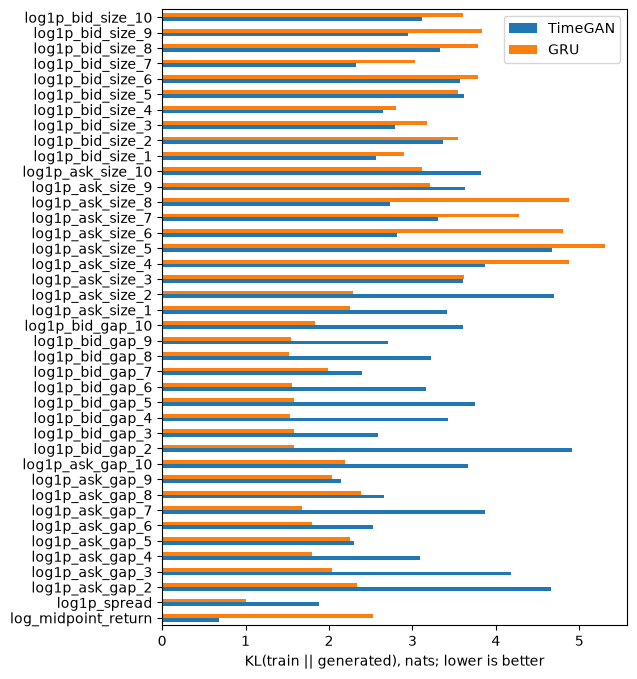

In [2]:
kl, ssim = compare_timegan_gru(model, data)
display(ssim.round(4))
kl.plot.barh(figsize=(6, 8), xlabel="KL(train || generated), nats; lower is better");